In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    # ローカル環境の場合、プロジェクトルートをパスに追加
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.4 メモリマップ (UEFI Memory Map Concept)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.4_UEFI_Memory_Map_Concept.ipynb)

本節では、名著『ゼロからのOS自作入門』第2章「EDK II入門とメモリマップ」の **2.4「メモリマップ」** を徹底解説します。

前節（2.3節）では、コンピュータの物理アドレス空間が単一で平坦なRAMではなく、**RAM（DRAM）、MMIO（周辺機器レジスタ）、ファームウェアROM、そして何も繋がっていない未実装領域（ホール）がモザイク状に散らばったスパース（疎）な空間**であることを学びました。

ここから自作OSカーネルを安全に物理メモリ上に配置し、ページテーブルやスタックを構築して起動するためには、ファームウェア（UEFI）から**「どの物理アドレスに、どれだけの大きさの、どのような性質のメモリが存在するのか」** を正確に記録した台帳を受け取る必要があります。この台帳こそが **「メモリマップ（Memory Map）」** です。

本ノートブックでは、UEFI仕様に規定されたメモリディスクリプタ構造体（`EFI_MEMORY_DESCRIPTOR`）のバイナリレイアウト、全16種のメモリタイプ（`EFI_MEMORY_TYPE`）の役割とOSライフサイクル、キャッシュ・保護属性ビットマスク、そしてC言語プログラマが必ず一度はハマる**可変長ディスクリプタのポインタ加算の罠**まで、完全自己完結で深く理解できるように解説・検証します。

---

### 📋 本節の学習目標と到達基準 (Definition of Done)
1. **メモリマップの存在意義（動機と課題）**:
   - なぜOS起動時にメモリマップが必要なのか、メモリマップがないとどのような致命的障害（暴走・上書き破壊）が発生するかを説明できる。
2. **`EFI_MEMORY_DESCRIPTOR` 構造体のメモリレイアウト**:
   - 40バイトの構造体サイズ、x86-64 ABIにおける自然アライメント（4バイトパディングの理由）、64ビット物理アドレス・ページ数・属性ビットの配置を数理的に導出できる。
3. **`EFI_MEMORY_TYPE` 全16種の完全分類とOSライフサイクル**:
   - `EfiConventionalMemory`（即時利用可能RAM）、`EfiBootServicesCode/Data`（`ExitBootServices()` 後回収可能）、`EfiRuntimeServicesCode/Data`（OS実行中も永続保護必須）などの決定的な役割の違いを区別できる。
4. **属性フラグ（`Attribute`）とキャッシュ・保護ポリシー**:
   - キャッシュ属性（UC, WC, WT, WB）、メモリ保護（WP, RP, XP）、および最上位ビット `EFI_MEMORY_RUNTIME` の意味を理解する。
5. **可変長ディスクリプタとポインタ演算の数理**:
   - なぜ `desc++`（配列インデックス参照）が致命的なバグを引き起こすのか、バイト単位のポインタ演算（`iter += descriptor_size`）が絶対必須である理由を数理的に実証する。
6. **C++20 / Python によるメモリマップ解析シミュレーション**:
   - ホスト環境でメモリディスクリプタの走査・集計・シリアライズ・視覚化コードを実行し、実際の挙動を対話的に確認する。


## 2.4.1 なぜOS起動にメモリマップが不可欠なのか？（動機と前節からの課題）

### 前節の振り返りと直面する問題
前節（2.3節）で学んだ通り、PCの物理アドレス空間には様々なハードウェア領域が混在しています：
- **通常のRAM（DRAM）**: プログラムコードやデータを自由に読み書きできる空間
- **MMIO（Memory-Mapped I/O）**: グラフィックボード（VRAM）、Local APIC、PCIeデバイスの制御レジスタ
- **ファームウェアROM**: UEFI BIOSのコードが格納された読み出し専用領域
- **メモリホール（未実装空間）**: バス上に何も接続されていない空白領域

もしブートローダやOSカーネルが、メモリ構造を調べずに適当なアドレス（例えば `0x10000000` や `0xC0000000`）にカーネルバイナリを展開したりスタックを置いたりしたら何が起きるでしょうか？

```text
[メモリマップなしの危険な配置シナリオ]
  アドレス 0xC0000000 にカーネルをロードしようとした！
       ↓
  実はそこは画面表示用 VRAM (MMIO領域) だった！
       ↓
  プログラムコードを書き込んだつもりが、画面に砂嵐ノイズが表示され、
  CPUが命令フェッチしようとするとバスエラー (Bus Fault / Machine Check) で即時PC停止！
```

### レガシーBIOS vs UEFI のメモリ検出
OSが安全にメモリを認識するために、PCファームウェアは昔からメモリ構造をOSに報告する仕組みを提供してきました：

| 時代 | ファームウェア | メモリ検出メカニズム | 課題・特徴 |
|:---:|:---:|---|---|
| **レガシーBIOS** | BIOS (16-bit) | `INT 15h, AX=E820h` (SMAP) | 16ビットリアルモードでしか呼び出せない。<br>構造体サイズや拡張性に制限があり、アドレス境界のパディング処理が煩雑。 |
| **現代のUEFI** | UEFI BIOS (64-bit) | `gBS->GetMemoryMap()` | 64ビットロングモードで直接呼び出し可能。<br>ページ単位（4KiB）の厳密な領域分割と、キャッシュ属性（Attribute）・ライフサイクル（Boot vs Runtime）まで完全通知。 |

以下のダイアグラムは、メモリマップを持たない「盲目ブート」の破綻と、メモリマップを活用した「安全なカーネル起動」の対比を示しています。

```mermaid
flowchart TD
    subgraph Danger["❌ メモリマップなしの盲目ブート (Blind Boot)"]
        D1["適当な物理アドレスを決め打ちしてカーネル配置"] --> D2{"そのアドレスは本当にRAMか？"}
        D2 -- No --> D3["MMIOやROM、未実装ホールに衝突"]
        D3 --> D4["マシンチェック例外 / クラッシュ・再起動"]
        D2 -- Yes --> D5{"UEFI自身やACPIテーブルを破壊していないか？"}
        D5 -- No --> D6["ファームウェアデータ破壊でExitBootServices不能"]
    end

    subgraph Safe["✅ メモリマップに基づく安全なブート (Safe Boot)"]
        S1["gBS->GetMemoryMap() でメモリ台帳を取得"] --> S2["全ディスクリプタを走査"]
        S2 --> S3["Type == EfiConventionalMemory の空きRAM領域を特定"]
        S3 --> S4["カーネルサイズ以上の連続4KiBページを安全に確保"]
        S4 --> S5["カーネルをロードし、ExitBootServices後に全ブートメモリを回収！"]
    end
```


## 2.4.2 UEFI メモリディスクリプタ構造体 (`EFI_MEMORY_DESCRIPTOR`) の完全解剖

### C言語構造体の定義 (UEFI Specification Section 7.2)
UEFI において、メモリの各領域（チャンク）の情報は **`EFI_MEMORY_DESCRIPTOR`** という構造体で表現されます。EDK II のヘッダ（`MdePkg/Include/Uefi/UefiSpec.h`）には以下のように定義されています：

```c
typedef struct {
    UINT32                Type;           // 0x00 - 0x03 (4 bytes): メモリの種類 (EFI_MEMORY_TYPE)
    UINT32                Pad;            // 0x04 - 0x07 (4 bytes): 64bit境界整列パディング
    EFI_PHYSICAL_ADDRESS  PhysicalStart;  // 0x08 - 0x0F (8 bytes): 物理開始アドレス
    EFI_VIRTUAL_ADDRESS   VirtualStart;   // 0x10 - 0x17 (8 bytes): 仮想開始アドレス
    UINT64                NumberOfPages;  // 0x18 - 0x1F (8 bytes): 4KiBページの個数
    UINT64                Attribute;      // 0x20 - 0x27 (8 bytes): キャッシュ・保護属性フラグ
} EFI_MEMORY_DESCRIPTOR;                  // 合計サイズ: 40 bytes (0x28)
```

### フィールド詳細と数理モデル

1. **`UINT32 Type` (オフセット `0x00`, 4バイト)**:
   - この領域が「通常の空きRAM」なのか「MMIO」なのか「ファームウェアコード」なのかを示す列挙値（後述の `EFI_MEMORY_TYPE`）。
2. **`UINT32 Pad` (オフセット `0x04`, 4バイト)**:
   - x86-64 アーキテクチャの自然アライメント（Natural Alignment）の要件により、直後の 64ビット整数 `PhysicalStart` を8の倍数アドレスに配置するための4バイトパディングです。
3. **`EFI_PHYSICAL_ADDRESS PhysicalStart` (オフセット `0x08`, 8バイト / 64ビット)**:
   - 領域の先頭物理メモリアドレス。UEFI仕様により、必ず **4KiB（4096バイト = `0x1000`）境界に整列**していなければなりません：
     $$	ext{PhysicalStart} \pmod{4096} = 0$$
4. **`EFI_VIRTUAL_ADDRESS VirtualStart` (オフセット `0x10`, 8バイト / 64ビット)**:
   - 領域の仮想アドレス。ブートローダ実行中（物理アドレス＝仮想アドレスの恒等マッピング時）は通常 `0` となっています。OSカーネルが `SetVirtualAddressMap()` を呼んでページングを設定する際に使われます。
5. **`UINT64 NumberOfPages` (オフセット `0x18`, 8バイト / 64ビット)**:
   - この領域のサイズを **4KiBページ数** で表した値です。バイト数ではありません！
   - 領域の総バイト数 $S$ および終了物理アドレス $E$ は以下の数理式で計算されます：
     $$S = 	ext{NumberOfPages} 	imes 4096 = 	ext{NumberOfPages} \ll 12$$
     $$E = 	ext{PhysicalStart} + S = 	ext{PhysicalStart} + (	ext{NumberOfPages} \ll 12)$$
6. **`UINT64 Attribute` (オフセット `0x20`, 8バイト / 64ビット)**:
   - CPUキャッシュの動作モード（Write-Back, Uncacheable など）やアクセス保護（実行禁止、書き込み禁止）を示すビットマスクです。

```text
+------------------------------------------------------------------------------------------------+
| EFI_MEMORY_DESCRIPTOR メモリレイアウト (合計 40 バイト = 0x28 バイト)                          |
+-------------------+-------------------+-----------------------------------+--------------------+
| 0x00 - 0x03 (4B)  | 0x04 - 0x07 (4B)  | 0x08 - 0x0F (8B)                  | 0x10 - 0x17 (8B)   |
| Type (UINT32)     | Pad (UINT32)      | PhysicalStart (64bit uint)        | VirtualStart (64b) |
+-------------------+-------------------+-----------------------------------+--------------------+
| 0x18 - 0x1F (8B)                      | 0x20 - 0x27 (8B)                                       |
| NumberOfPages (64bit uint)            | Attribute (64bit bitmask)                              |
+---------------------------------------+--------------------------------------------------------+
```


In [2]:
# EFI_MEMORY_DESCRIPTOR 構造体のバイナリパッキングとオフセット検証
import struct

# EFI_MEMORY_DESCRIPTOR のフォーマット文字列:
# < : リトルエンディアン (x86-64 標準)
# I : UINT32 (4バイト)
# I : UINT32 (4バイト / Pad)
# Q : UINT64 (8バイト / PhysicalStart)
# Q : UINT64 (8バイト / VirtualStart)
# Q : UINT64 (8バイト / NumberOfPages)
# Q : UINT64 (8バイト / Attribute)
desc_fmt = "<IIQQQQ"
struct_size = struct.calcsize(desc_fmt)

print(f"EFI_MEMORY_DESCRIPTOR 構造体の計算サイズ: {struct_size} バイト (0x{struct_size:X})")
assert struct_size == 40, f"Expected 40 bytes, got {struct_size}"

# サンプルディスクリプタのパッキング（1MBから127MBのConventional RAM）
sample_type = 7           # EfiConventionalMemory
sample_pad = 0
sample_phys = 0x00100000  # 1MB
sample_virt = 0x00000000
sample_pages = 32512      # 32512 pages * 4096 = 133,169,152 bytes (127 MiB)
sample_attr = 0x0000000F  # WB | WT | WC | UC

raw_bytes = struct.pack(desc_fmt, sample_type, sample_pad, sample_phys, sample_virt, sample_pages, sample_attr)
print(f"パッキング後のバイナリ長: {len(raw_bytes)} bytes")
print("16進数ダンプ:", " ".join(f"{b:02X}" for b in raw_bytes))

# アンパック検証
u_type, u_pad, u_phys, u_virt, u_pages, u_attr = struct.unpack(desc_fmt, raw_bytes)
print(f"\n[アンパック復元結果]")
print(f"  Type:          {u_type} (EfiConventionalMemory)")
print(f"  PhysicalStart: 0x{u_phys:08X}")
print(f"  NumberOfPages: {u_pages} pages ({u_pages * 4096 / (1024*1024):.1f} MiB)")
print(f"  PhysicalEnd:   0x{u_phys + u_pages * 4096:08X}")
print(f"  Attribute:     0x{u_attr:X}")


EFI_MEMORY_DESCRIPTOR 構造体の計算サイズ: 40 バイト (0x28)
パッキング後のバイナリ長: 40 bytes
16進数ダンプ: 07 00 00 00 00 00 00 00 00 00 10 00 00 00 00 00 00 00 00 00 00 00 00 00 00 7F 00 00 00 00 00 00 0F 00 00 00 00 00 00 00

[アンパック復元結果]
  Type:          7 (EfiConventionalMemory)
  PhysicalStart: 0x00100000
  NumberOfPages: 32512 pages (127.0 MiB)
  PhysicalEnd:   0x08000000
  Attribute:     0xF


## 2.4.3 EFI_MEMORY_TYPE 全16種の完全分類とOSにとっての意味

UEFI 仕様書 Section 7.2 に定義されている `EFI_MEMORY_TYPE` 列挙型には、16種類のメモリタイプが存在します。  
OS自作において、**「どのメモリタイプが何を意味し、OSがどう扱わなければならないか」** を理解することは極めて重要です。

### 全16種のメモリタイプ一覧表

| 値 | 列挙名 (Type Name) | 主な用途・説明 | OSにとっての扱い（ライフサイクル） |
|:---:|---|---|---|
| `0` | `EfiReservedMemoryType` | ファームウェア内部で予約された領域 | **OS使用禁止**。絶対に上書きしてはならない。 |
| `1` | `EfiLoaderCode` | UEFIブートローダ（`BOOTX64.EFI`）の実行可能コード | ブート中は使用中。カーネル起動完了後は **解放・再利用可能**。 |
| `2` | `EfiLoaderData` | UEFIブートローダが確保したデータ・スタック | ブート中は使用中。カーネル起動完了後は **解放・再利用可能**。 |
| `3` | `EfiBootServicesCode` | UEFIブートサービスの実行可能コード | ブート中はUEFIが使用。`ExitBootServices()` 後は **解放・再利用可能**！ |
| `4` | `EfiBootServicesData` | UEFIブートサービスが使用するヒープ・作業メモリ | ブート中はUEFIが使用。`ExitBootServices()` 後は **解放・再利用可能**！ |
| `5` | `EfiRuntimeServicesCode` | UEFIランタイムサービスの実行可能コード | **OS起動後も存続必須**！仮想メモリ空間へマッピングが必要。 |
| `6` | `EfiRuntimeServicesData` | UEFIランタイムサービスの作業データ | **OS起動後も存続必須**！仮想メモリ空間へマッピングが必要。 |
| `7` | **`EfiConventionalMemory`** | **純粋な空きRAM（最も重要！）** | **OSが直ちにカーネル・スタック・ヒープに自由に使用可能**！ |
| `8` | `EfiUnusableMemory` | パリティエラー等のハードウェア障害が検出されたRAM | **OS使用禁止**。アクセスするとCPUエラーが発生する。 |
| `9` | `EfiACPIReclaimMemory` | ACPIテーブル（電源管理情報・MADT・FADT等） | OSがACPI情報を解析・読み取った後は **解放してRAMとして再利用可能**。 |
| `10`| `EfiACPIMemoryNVS` | ACPI不揮発性ストレージ領域 | **OS上書き禁止**。ファームウェアが状態保存に使用する。 |
| `11`| `EfiMemoryMappedIO` | ハードウェアの制御レジスタ（VRAM, APIC, PCIe BAR等） | **通常のRAMとして割り当て厳禁**！MMIOアクセス用。 |
| `12`| `EfiMemoryMappedIOPortSpace`| I/Oポート空間を物理メモリにマップした領域 | **RAM割り当て厳禁**。 |
| `13`| `EfiPalCode` | Itaniumプロセッサ等のプロセッサ抽象化コード | x86-64 では通常出現しない。保護が必要。 |
| `14`| `EfiPersistentMemory` | NVDIMM等の不揮発性バイトアドレサブルメモリ (PMEM) | 電源切断後もデータが残るRAM。永続記憶用。 |
| `15`| `EfiMaxMemoryType` | 列挙型の境界値チェック用マーカー | メモリタイプとしては使用されない。 |

---

### 💡 OSから見たメモリの3大分類

自作OSカーネルのメモリマネージャ（第8章の `BitmapMemoryManager`）を実装する際、OS開発者は上記の16種を以下の**3大グループ**に分類して扱います：

1. **グループ A: 最初からOSが自由に使える空き領域 (Free Usable RAM)**
   - `EfiConventionalMemory`
   - ブートローダがカーネルELFを展開する先として直ちに利用できます。
2. **グループ B: `ExitBootServices()` 呼び出し後に回収（Reclaim）できる領域**
   - `EfiBootServicesCode`, `EfiBootServicesData`, `EfiLoaderCode`, `EfiLoaderData`, `EfiACPIReclaimMemory`
   - UEFIが起動を終えて制御を完全にOSへ渡した後は、ブートサービスコードは不要になります。数十MBにおよぶこれらの領域を回収してOSのメモリプールに追加することで、貴重な物理RAMを最大限活用できます。
3. **グループ C: OS起動後も絶対に破壊してはならない保護領域 (Persistent Reserved)**
   - `EfiRuntimeServicesCode`, `EfiRuntimeServicesData`, `EfiACPIMemoryNVS`, `EfiMemoryMappedIO`, `EfiReservedMemoryType`
   - OS稼働中もUEFIの時刻取得（`GetTime`）やPCシャットダウン（`ResetSystem`）を呼び出すために必須です。ページテーブルで保護し、OSの汎用アロケータが決して上書きしないように隔離します。


## 2.4.4 メモリ属性フラグ (`Attribute`) とキャッシュ・保護ポリシー

`EFI_MEMORY_DESCRIPTOR` の最後のフィールド `Attribute` は、そのメモリ領域がハードウェア的にどのようなアクセス特性をサポートしているかを示す **64ビットのビットマスク** です。

### 主要な属性ビット (UEFI 2.10 Spec Table 7.3)

| ビット | マクロ定数 | 16進マスク | 意味と役割 |
|:---:|---|:---:|---|
| **0** | `EFI_MEMORY_UC` | `0x0000000000000001` | **Uncacheable**: キャッシュ無効。ハードウェアレジスタ（MMIO）に必須。 |
| **1** | `EFI_MEMORY_WC` | `0x0000000000000002` | **Write-Combining**: 書き込み結合。フレームバッファ（画面描画）の高速化に利用。 |
| **2** | `EFI_MEMORY_WT` | `0x0000000000000004` | **Write-Through**: キャッシュとメモリの両方に即時書き込み。 |
| **3** | `EFI_MEMORY_WB` | `0x0000000000000008` | **Write-Back**: 最速の通常キャッシュモード。通常のRAMはすべてこれに対応。 |
| **12**| `EFI_MEMORY_WP` | `0x0000000000001000` | **Write-Protect**: 書き込み保護（ハードウェアレベルのライトプロテクト）。 |
| **13**| `EFI_MEMORY_RP` | `0x0000000000002000` | **Read-Protect**: 読み出し保護。 |
| **14**| `EFI_MEMORY_XP` | `0x0000000000004000` | **Execute-Protect (No-Execute / NX)**: 実行禁止。データ領域やスタックに設定。 |
| **63**| **`EFI_MEMORY_RUNTIME`** | **`0x8000000000000000`** | **Runtime Memory**: **最重要！OSカーネル起動後も仮想アドレス空間へのマッピングが必須**。 |

> [!IMPORTANT]
> **最重要フラグ `EFI_MEMORY_RUNTIME` (ビット63)**:  
> このフラグが立っている領域は、OSが仮想記憶（Paging）を有効化した後も、CPUからアクセスできるようにページテーブル（CR3）にマッピングしておかなければなりません。もしマッピングを怠ると、OSがUEFIのシャットダウン関数などを呼んだ瞬間にページフォルト（Page Fault / `#PF`）でクラッシュします。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:7400: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Generated] result/fig2_07_efi_memory_descriptor_layout_and_attributes.png


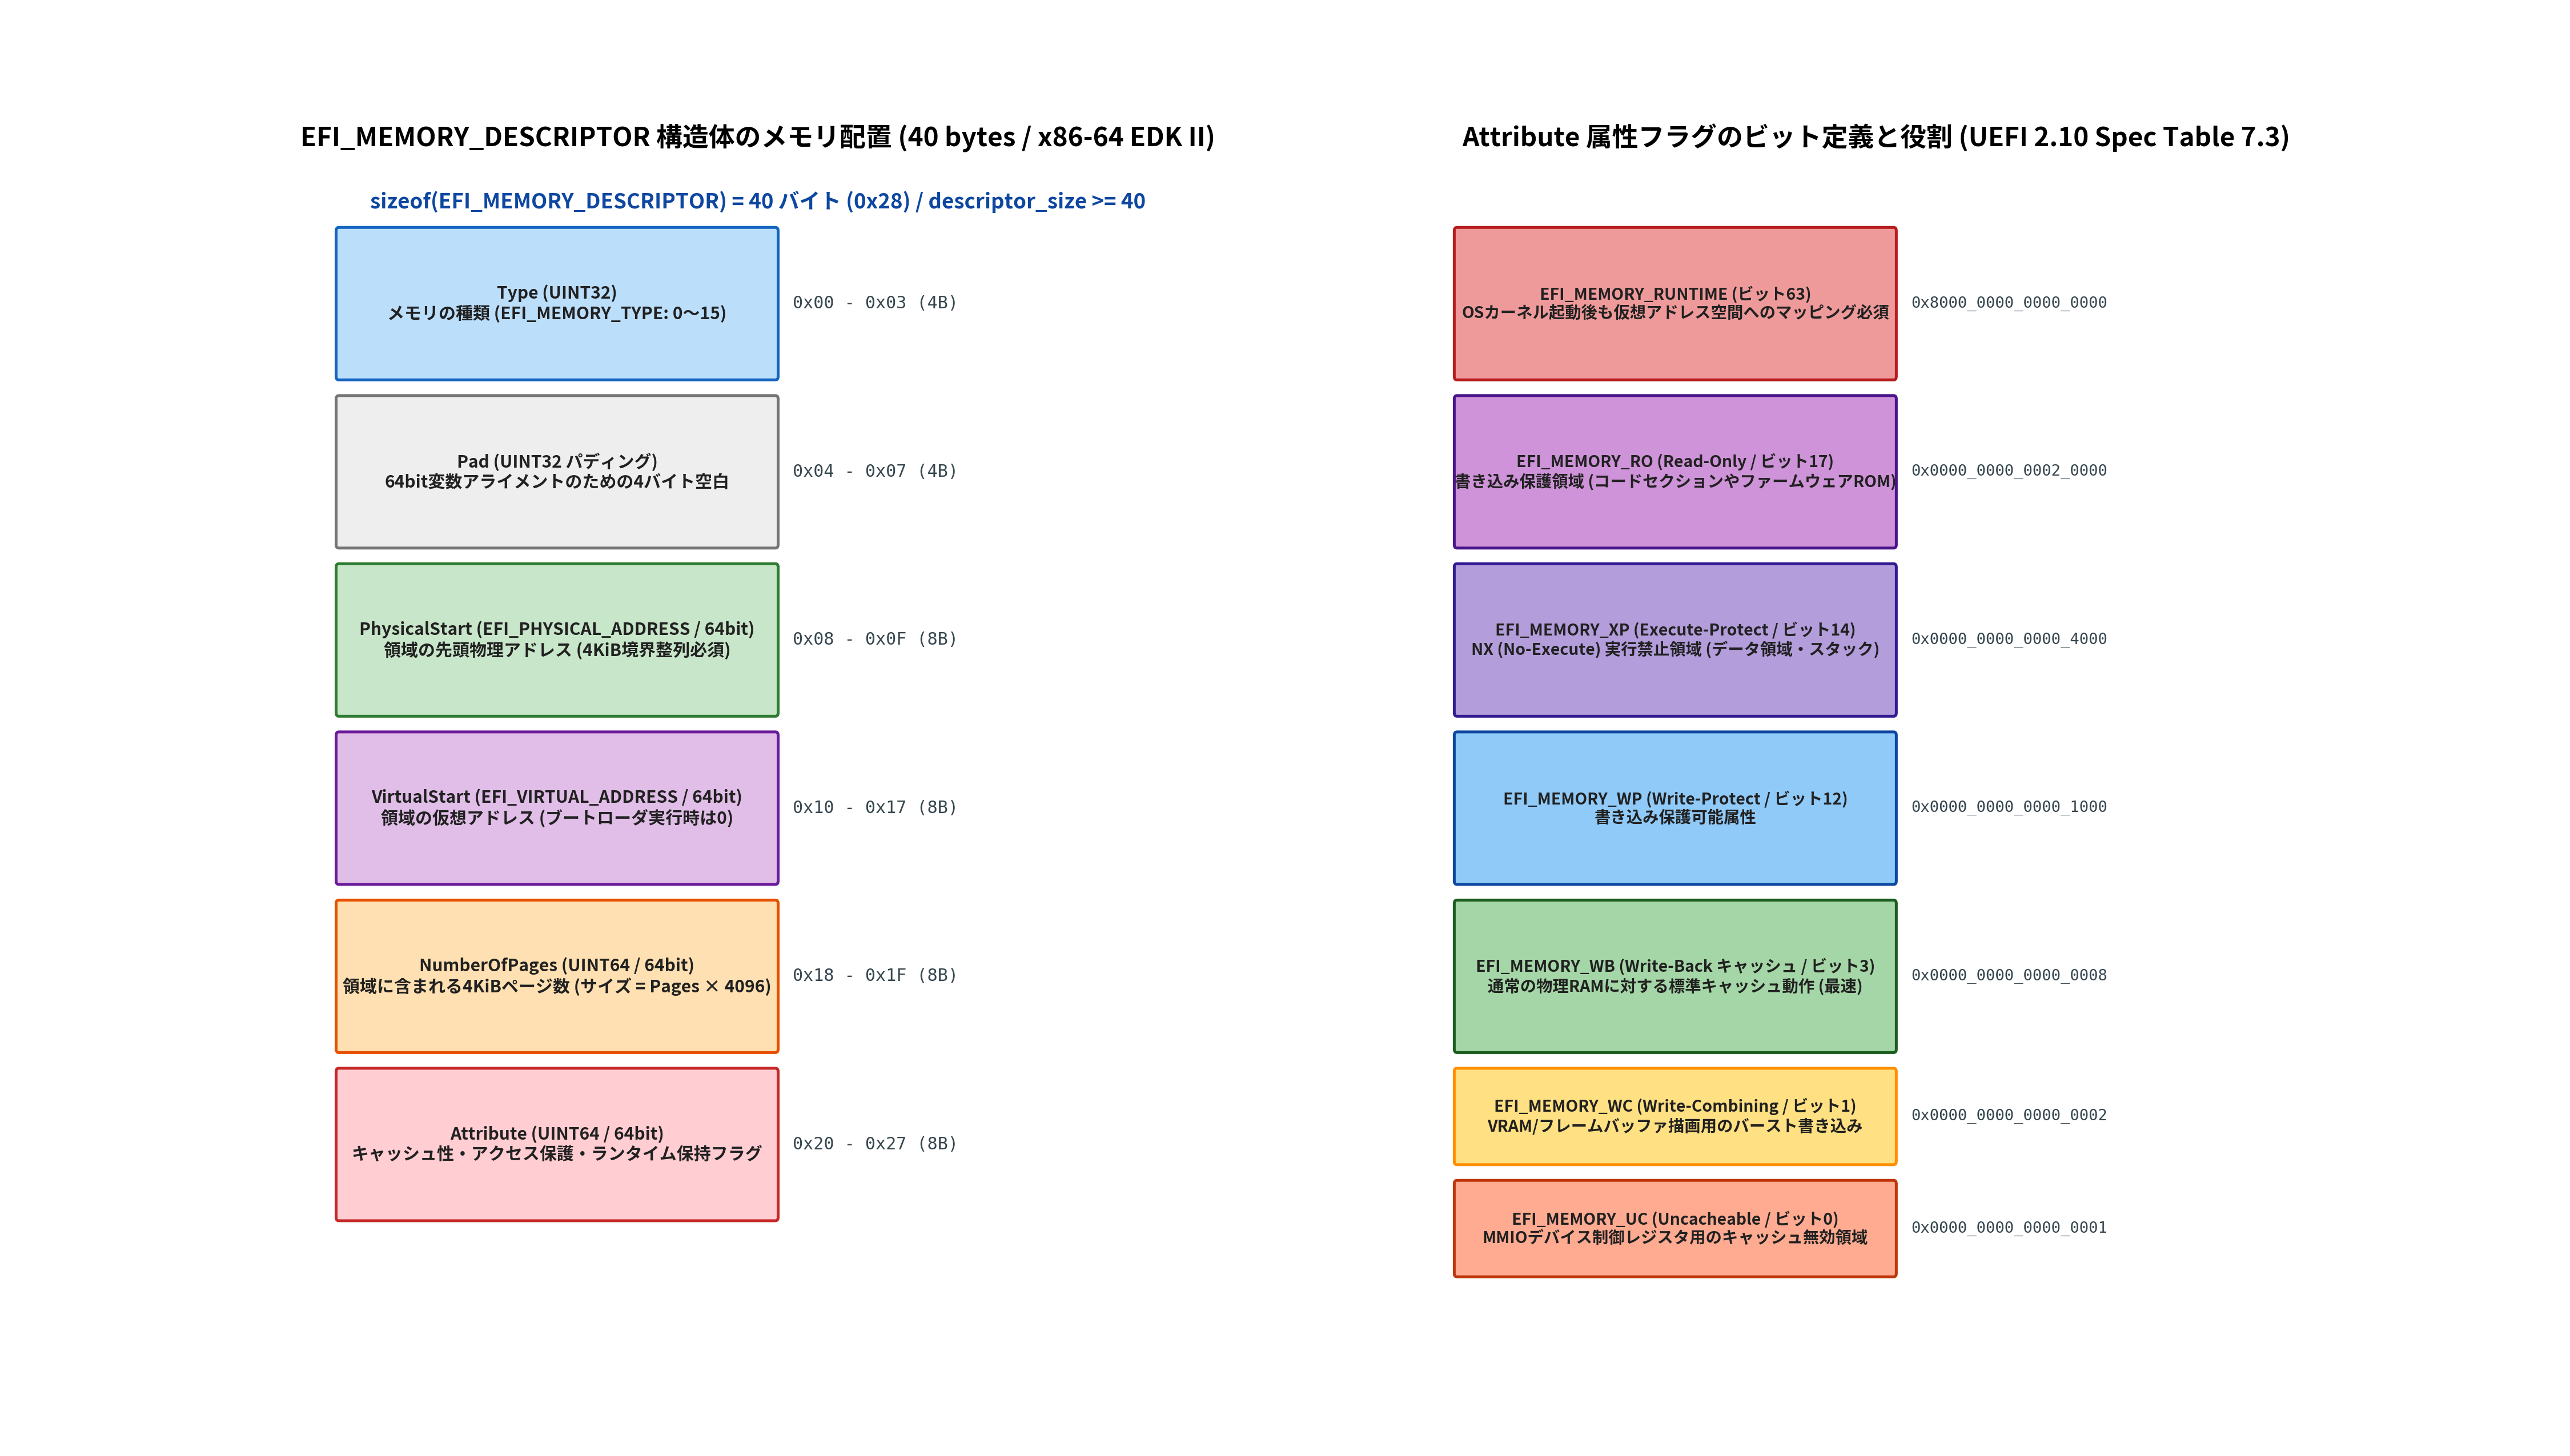

In [3]:
# 高解像度図版 Figure 2.7 の生成とインライン表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_efi_memory_descriptor_layout_and_attributes

fig2_07_path = Path("result/fig2_07_efi_memory_descriptor_layout_and_attributes.png")
if not fig2_07_path.exists():
    fig2_07_path = Path("2/result/fig2_07_efi_memory_descriptor_layout_and_attributes.png")

plot_efi_memory_descriptor_layout_and_attributes(str(fig2_07_path))
print(f"[Generated] {fig2_07_path}")
display(Image(filename=str(fig2_07_path)))


## 2.4.5 ExitBootServices() とメモリライフサイクルの劇的転換

自作OS開発における最重要の通過儀礼が **`gBS->ExitBootServices()` の呼び出し** です。  
このAPIを呼ぶことによって、PCの制御権はUEFIファームウェアから自作OSカーネルへと完全に移譲されます。

### ExitBootServices() 呼び出し前後の決定的な変化

```text
+---------------------------------------------------------------------------------------------------+
| 【フェーズ 1: UEFI ブートローダ実行中 (Boot Services 生存中)】                                    |
|   ・gBS (Boot Services) の全API (メモリ確保, 画面文字出力, ファイルI/O) が利用可能               |
|   ・UEFIファームウェア自身が大量の BootServicesCode / BootServicesData 領域をメモリ上に展開       |
|   ・OSが利用できる空きメモリは EfiConventionalMemory のみ                                        |
+---------------------------------------------------------------------------------------------------+
                                                  │
                                                  │ gBS->ExitBootServices(image_handle, map_key)
                                                  ▼
+---------------------------------------------------------------------------------------------------+
| 【フェーズ 2: ExitBootServices() 完了後 (OSカーネル単独稼働)】                                    |
|   ・UEFIのブートサービスAPIは全て消滅！ gBSポインタへのアクセスは未定義動作 (暴走・フリーズ)     |
|   ・不要になった BootServicesCode / BootServicesData (~数十MB) が一斉に解放可能となる！          |
|   ・OSはこれらの回収可能領域を ConventionalMemory と合体させて巨大な空きメモリプールを構築       |
|   ・ただし RuntimeServicesCode / RuntimeServicesData は引き続き保護・仮想マッピングが必要       |
+---------------------------------------------------------------------------------------------------+
```

以下の高解像度図版（Figure 2.8）は、メモリタイプの4大分類と、`ExitBootServices()` に伴うメモリ再利用ライフサイクルの推移を示しています。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:7465: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Generated] result/fig2_08_uefi_memory_types_classification_and_lifecycle.png


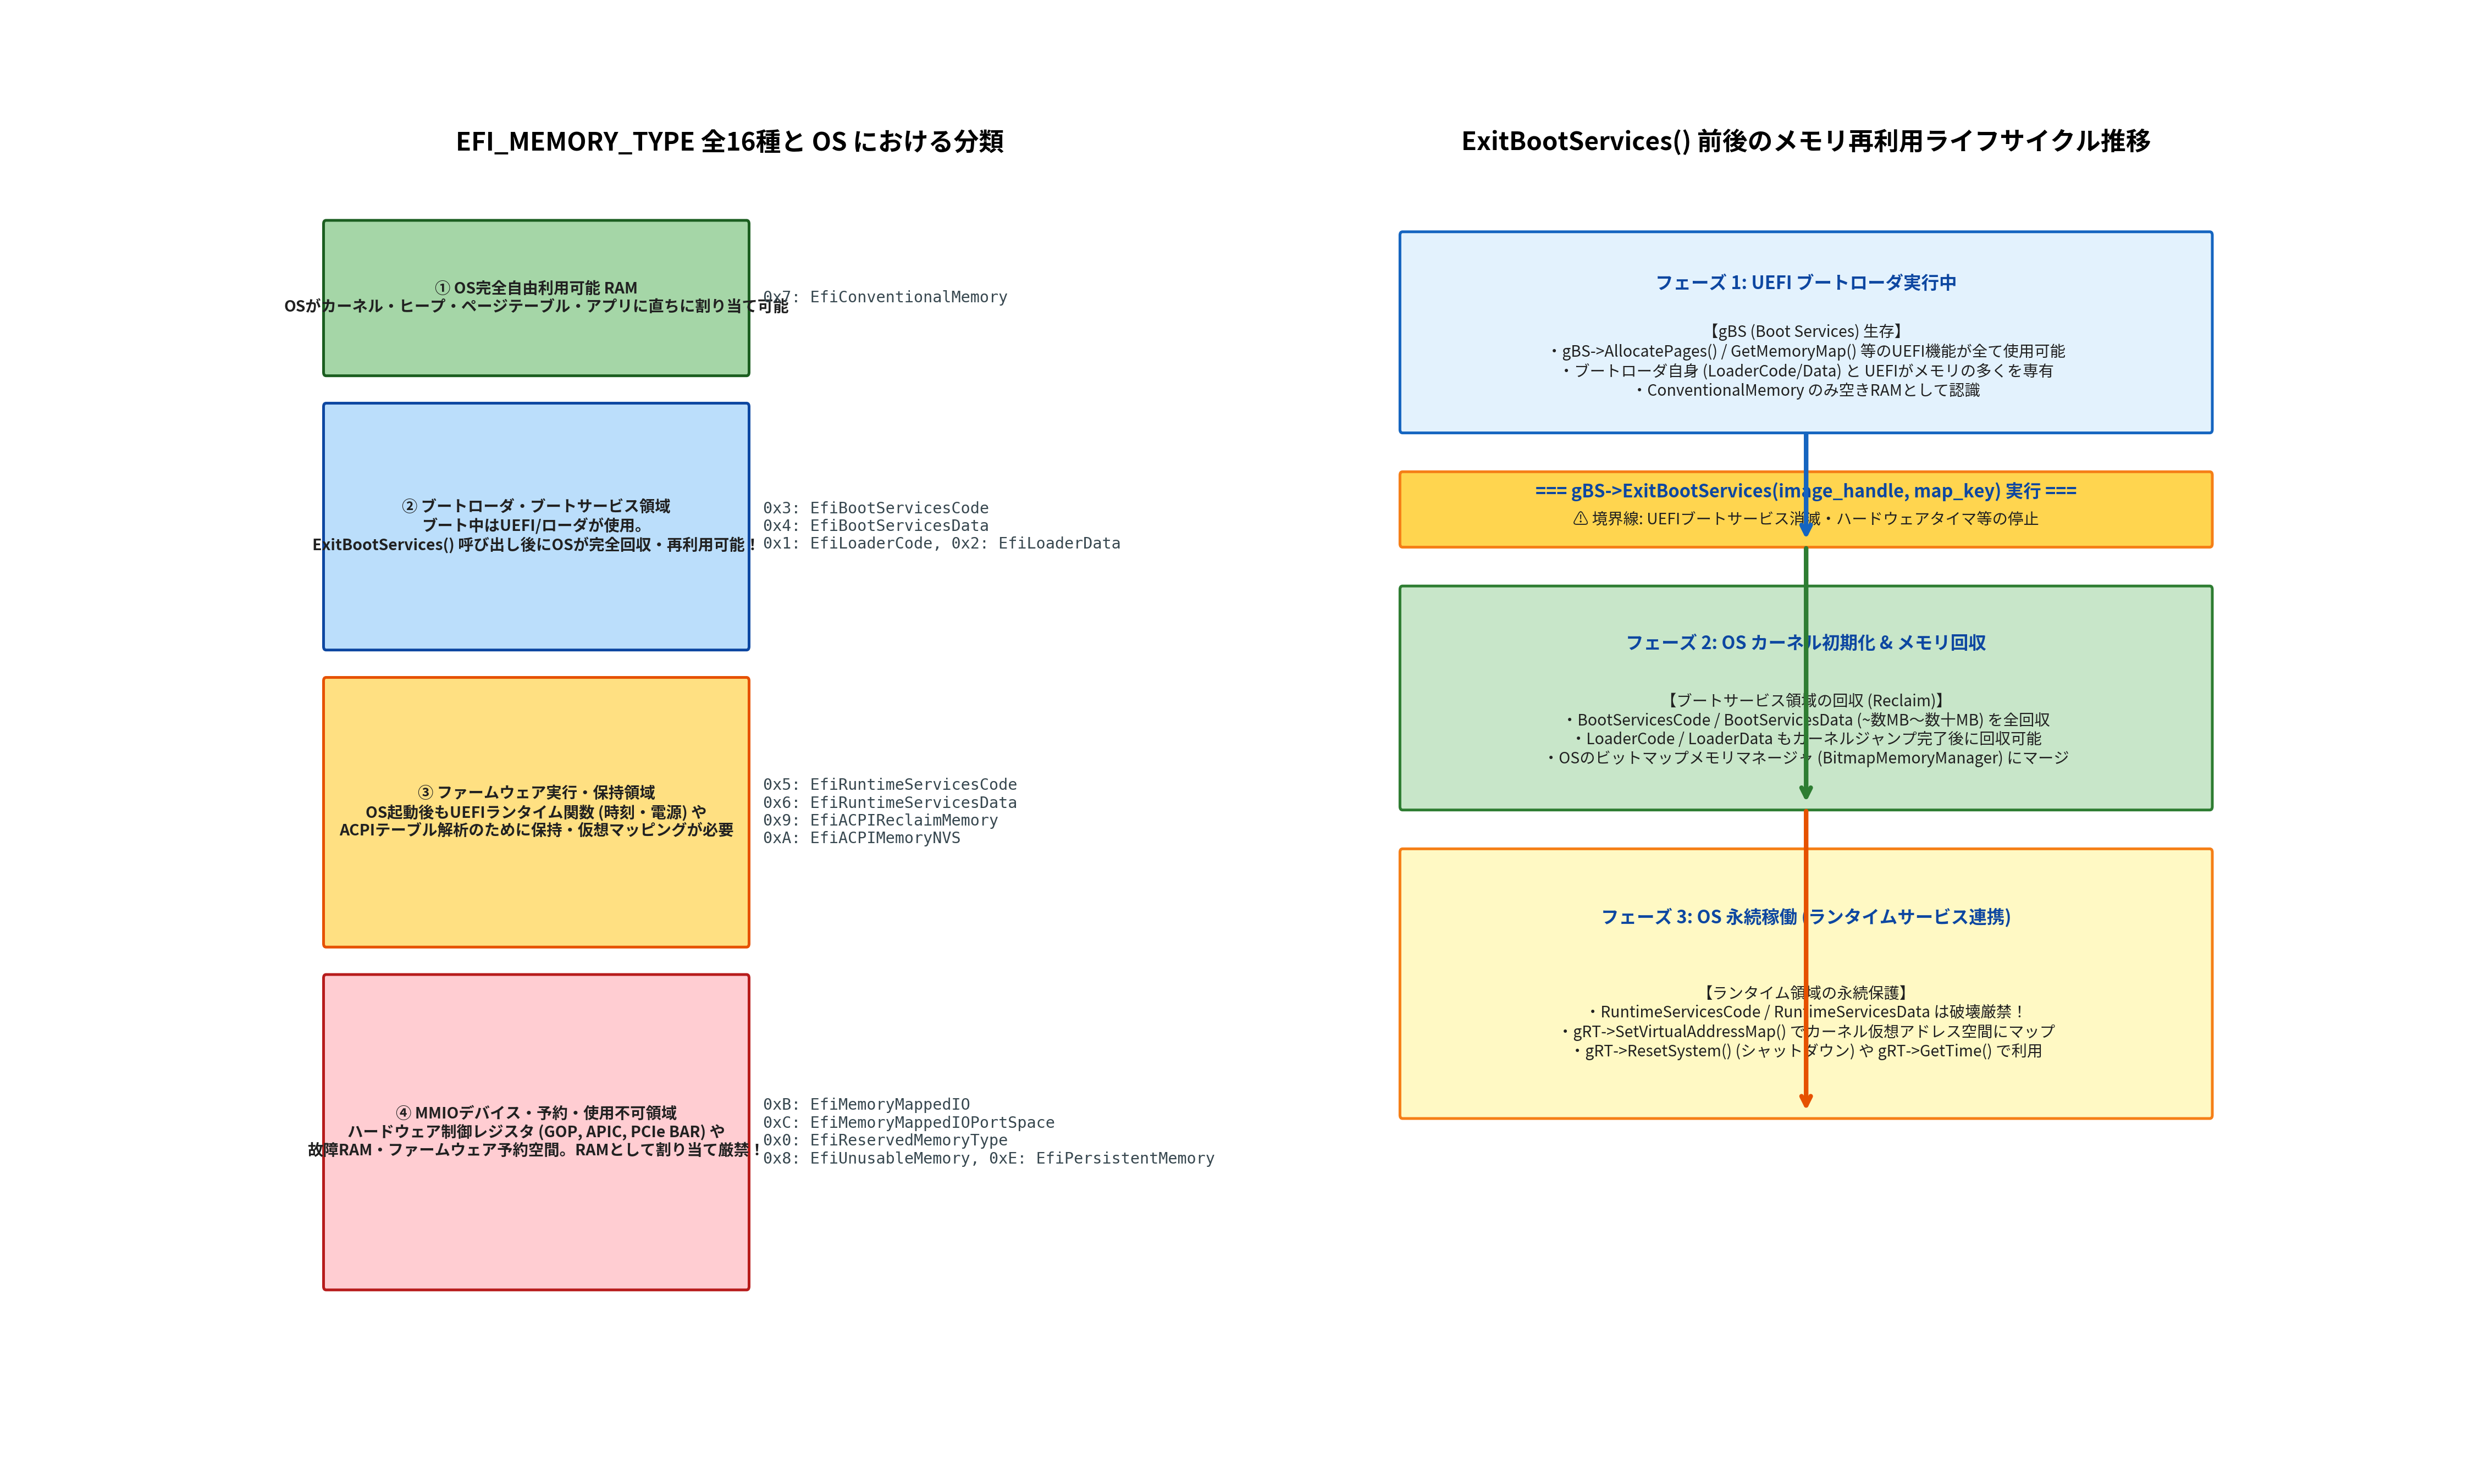

In [4]:
# 高解像度図版 Figure 2.8 の生成とインライン表示
from pathlib import Path
from IPython.display import Image, display
from common.os_sim import plot_uefi_memory_types_classification_and_lifecycle

fig2_08_path = Path("result/fig2_08_uefi_memory_types_classification_and_lifecycle.png")
if not fig2_08_path.exists():
    fig2_08_path = Path("2/result/fig2_08_uefi_memory_types_classification_and_lifecycle.png")

plot_uefi_memory_types_classification_and_lifecycle(str(fig2_08_path))
print(f"[Generated] {fig2_08_path}")
display(Image(filename=str(fig2_08_path)))


## 2.4.6 【最重要の罠】可変長ディスクリプタとポインタ演算の数理

ここが、**C言語・低レイヤ初心者が100%と言っていい確率でハマる最大の落とし穴**です。

### 陥りがちな致命的バグ：`desc++` や `desc[i]`

通常のC言語プログラミングであれば、構造体の配列をループ処理する際、以下のように書くのが自然です：

```c
// ❌ 破滅を招くコード！
EFI_MEMORY_DESCRIPTOR* desc = (EFI_MEMORY_DESCRIPTOR*)map->buffer;
for (int i = 0; i < count; i++) {
    // desc[i] や desc++ を使って走査
    Print(L"Type: %d, Start: %08lx\n", desc[i].Type, desc[i].PhysicalStart);
}
```

**なぜこのコードは絶対に書いてはいけないのでしょうか？**

### 数理的な理由：`descriptor_size != sizeof(EFI_MEMORY_DESCRIPTOR)`

C言語の言語仕様において、ポインタ加算 `desc + 1` や配列アクセス `desc[i]` は、**コンパイル時に確定している型サイズ `sizeof(EFI_MEMORY_DESCRIPTOR)`（＝ 40 バイト）単位** でアドレスを進めます：
$$	ext{Address}(	ext{desc}[i]) = 	ext{desc} + (i 	imes 40)$$

しかし、UEFI仕様書にはこう書かれています：
> *"The size of an `EFI_MEMORY_DESCRIPTOR` may change in future versions of this specification. Therefore, applications must use the `DescriptorSize` returned by `GetMemoryMap()` to advance to the next descriptor in the buffer."*  
> （将来のバージョンで構造体が拡張される可能性があるため、次のディスクリプタに進む際は必ず `GetMemoryMap()` が返した `DescriptorSize` を使用しなければならない）

現実に、QEMU OVMF や多くのPC環境では、64ビットアライメントや拡張のために **`DescriptorSize = 48` バイト（0x30）** が返されます！

### オフセットのズレとデータの完全破壊

もし `DescriptorSize = 48` なのに、コードが `desc++`（40バイト加算）を行うと、2番目以降の要素のオフセットが以下のようにズレていきます：

```text
[ファームウェアがメモリ上に配置したデータ (48バイト刻み)]
Offset 0:   [Desc 0: 40B 本体] [8B パディング]
Offset 48:  [Desc 1: 40B 本体] [8B パディング]
Offset 96:  [Desc 2: 40B 本体] [8B パディング]

[C言語の desc[i] が読み出す位置 (40バイト刻み)]
i = 0: Offset 0  -> 正しく Desc 0 の先頭を読み出せる！
i = 1: Offset 40 -> ❌ 48ではなく40を読む！Desc 0 の末尾パディングを Type と誤認！
i = 2: Offset 80 -> ❌ 96ではなく80を読む！Desc 1 の内部を斜めに読み出して全てがゴミデータに！
```

結果として、1番目の要素だけは正常に見えるものの、**2番目以降のメモリタイプやアドレスが完全に壊れてデタラメな値になり、OSが確実にクラッシュ**します。

---

### 正しいイテレーション方法（バイト単位ポインタ加算）

この問題を回避するため、MikanOS のブートローダでは、ポインタを一旦バイト単位（`EFI_PHYSICAL_ADDRESS` または `uintptr_t` / `uint8_t*`）として扱い、ファームウェアが返した **`map->descriptor_size` をバイト加算**してから構造体ポインタへキャストします：

```c
// ✅ 正しいディスクリプタ走査イテレーション
EFI_PHYSICAL_ADDRESS iter;
int i;
for (iter = (EFI_PHYSICAL_ADDRESS)map->buffer, i = 0;
     iter < (EFI_PHYSICAL_ADDRESS)map->buffer + map->map_size;
     iter += map->descriptor_size, i++) {
    EFI_MEMORY_DESCRIPTOR* desc = (EFI_MEMORY_DESCRIPTOR*)iter;
    // desc を安全に利用できる！
}
```


In [5]:
# C言語の desc++ バグ vs バイト加算 iter += descriptor_size の実証実験
import struct
from common.os_sim import UefiMemoryDescriptor, UefiMemoryType, EFI_MEMORY_WB

# 2つのディスクリプタを作成
d0 = UefiMemoryDescriptor(UefiMemoryType.EfiBootServicesCode, 0x00000000, 0, 159, EFI_MEMORY_WB)
d1 = UefiMemoryDescriptor(UefiMemoryType.EfiConventionalMemory, 0x00100000, 0, 1024, EFI_MEMORY_WB)

# ファームウェアが返す descriptor_size = 48 バイトでバッファを作成（末尾に8バイトのゼロパディングが付く）
desc_size = 48
buffer = d0.to_bytes(desc_size) + d1.to_bytes(desc_size)
print(f"バッファ全体のサイズ: {len(buffer)} バイト (48B × 2要素)")

print("\n--- ✅ 正しい走査: iter += descriptor_size (48バイト加算) ---")
iter_0 = 0
desc0_correct = UefiMemoryDescriptor.from_bytes(buffer[iter_0 : iter_0 + desc_size], desc_size)
print(f"[要素 0] Offset {iter_0:2d}: Type = {desc0_correct.type.name:23s}, Start = 0x{desc0_correct.physical_start:08X}")

iter_1 = iter_0 + desc_size
desc1_correct = UefiMemoryDescriptor.from_bytes(buffer[iter_1 : iter_1 + desc_size], desc_size)
print(f"[要素 1] Offset {iter_1:2d}: Type = {desc1_correct.type.name:23s}, Start = 0x{desc1_correct.physical_start:08X}")
assert desc1_correct.type == UefiMemoryType.EfiConventionalMemory
assert desc1_correct.physical_start == 0x00100000

print("\n--- ❌ 誤った走査: desc++ (sizeof = 40バイト加算) ---")
bug_iter_0 = 0
desc0_bug = UefiMemoryDescriptor.from_bytes(buffer[bug_iter_0 : bug_iter_0 + 40], 40)
print(f"[要素 0] Offset {bug_iter_0:2d}: Type = {desc0_bug.type.name:23s}, Start = 0x{desc0_bug.physical_start:08X} (※正常に見える)")

bug_iter_1 = bug_iter_0 + 40  # sizeof(EFI_MEMORY_DESCRIPTOR) = 40バイト進めてしまった！
desc1_bug = UefiMemoryDescriptor.from_bytes(buffer[bug_iter_1 : bug_iter_1 + 40], 40)
print(f"[要素 1] Offset {bug_iter_1:2d}: Type = {desc1_bug.type.name:23s}, Start = 0x{desc1_bug.physical_start:08X} (💥データ破壊！)")

print("\n結論: 要素1のオフセットが8バイト手前にズレたため、パディングの 0x00 を読み込んでしまい、")
print(f"      本来 EfiConventionalMemory (7) であるはずが '{desc1_bug.type.name}' と誤認されました！")


バッファ全体のサイズ: 96 バイト (48B × 2要素)

--- ✅ 正しい走査: iter += descriptor_size (48バイト加算) ---
[要素 0] Offset  0: Type = EfiBootServicesCode    , Start = 0x00000000
[要素 1] Offset 48: Type = EfiConventionalMemory  , Start = 0x00100000

--- ❌ 誤った走査: desc++ (sizeof = 40バイト加算) ---
[要素 0] Offset  0: Type = EfiBootServicesCode    , Start = 0x00000000 (※正常に見える)
[要素 1] Offset 40: Type = EfiReservedMemoryType  , Start = 0x00000007 (💥データ破壊！)

結論: 要素1のオフセットが8バイト手前にズレたため、パディングの 0x00 を読み込んでしまい、
      本来 EfiConventionalMemory (7) であるはずが 'EfiReservedMemoryType' と誤認されました！


## 2.4.7 対話型 C++20 コンパイル実行：メモリマップ解析・ポインタ演算シミュレータ

リポジトリの `src/ch02/uefi_memory_map_concept_sim.cpp` には、UEFI 仕様に厳密に準拠した C++20 実装が含まれています：
- `EFI_MEMORY_DESCRIPTOR` 構造体のアライメントとオフセット検証（`static_assert`）
- 40バイト vs 48バイト/64バイト可変長ディスクリプタのポインタステッピング検証
- QEMU OVMF 4GB RAM メモリマップの解析・空きRAM集計アルゴリズム

以下のセルを実行して、ホスト側の C++20 コンパイラでビルド・単体テストを実行してみましょう。


In [6]:
# C++20 スタンドアロンシミュレータのビルドとテスト実行
import subprocess
from pathlib import Path

# CMake ビルドの実行
build_res = subprocess.run(["cmake", "--build", "build", "--target", "ch02_uefi_memory_map_concept_sim"],
                           capture_output=True, text=True)
if build_res.returncode != 0:
    # カレントディレクトリが 2/ の場合のフォールバック
    build_res = subprocess.run(["cmake", "--build", "../build", "--target", "ch02_uefi_memory_map_concept_sim"],
                               capture_output=True, text=True)

print("CMake ビルド出力:\n", build_res.stdout)

# 実行可能ファイルの探索
bin_candidates = [
    Path("build/bin/ch02_uefi_memory_map_concept_sim"),
    Path("../build/bin/ch02_uefi_memory_map_concept_sim"),
    Path("build/ch02_uefi_memory_map_concept_sim"),
    Path("../build/ch02_uefi_memory_map_concept_sim"),
]
sim_bin = next((p for p in bin_candidates if p.exists()), None)
assert sim_bin is not None, "ch02_uefi_memory_map_concept_sim executable not found"

# 1. セルフテストの実行
test_res = subprocess.run([str(sim_bin), "--test"], capture_output=True, text=True)
print("=== C++20 単体テスト実行結果 ===")
print(test_res.stdout)
assert test_res.returncode == 0, f"Self-test failed: {test_res.stderr}"

# 2. メモリマップダンプ実行
dump_res = subprocess.run([str(sim_bin)], capture_output=True, text=True)
print("=== メモリマップ解析ダンプ出力 ===")
print(dump_res.stdout)


CMake ビルド出力:
 [100%] Built target ch02_uefi_memory_map_concept_sim

=== C++20 単体テスト実行結果 ===
[TEST] Running UEFI Memory Map & Descriptor Verification Tests...
  ✓ EFI_MEMORY_DESCRIPTOR struct alignment & offsets verified (40 bytes)
  ✓ Standard UEFI Memory Map created with 13 descriptors
  ✓ 48-byte descriptor serialization & deserialization passed
  ✓ Extended 64-byte descriptor pointer stepping verified (iter += descriptor_size)
  ✓ Conventional free RAM calculation verified: 4123 MiB
  ✓ BootServices reclaimable memory calculation verified: 2172 KiB
[SUCCESS] All UEFI Memory Map self-tests passed cleanly!

=== メモリマップ解析ダンプ出力 ===
🍊 MikanOS EDK II EFI_MEMORY_DESCRIPTOR & Memory Map Inspector

Idx  Type (Name)                 PhysicalStart     NumberOfPages SizeBytes     Attribute
------------------------------------------------------------------------------------------
0    EfiBootServicesCode         0x000000000000    159           636 KiB       0xf
1    EfiReservedMemoryType       0x0

## 2.4.8 Python による UEFI メモリマップ解析・集計・視覚化実験

共通パッケージ `common.os_sim` に実装された `UefiMemoryMapSimulator` を使用して、QEMU OVMF 4GB RAM マシンのメモリ構成を対話的に集計し、各メモリタイプの割合を可視化してみましょう。


📊 メモリマップ集計結果 (全 13 エントリ):
  ・初期空きRAM (Conventional):     4123.5 MiB (4.03 GiB)
  ・ExitBootServices後回収可能RAM:  2172.0 KiB (2.12 MiB)
  ・ランタイムサービス保持領域:      1280.0 KiB (1.25 MiB)


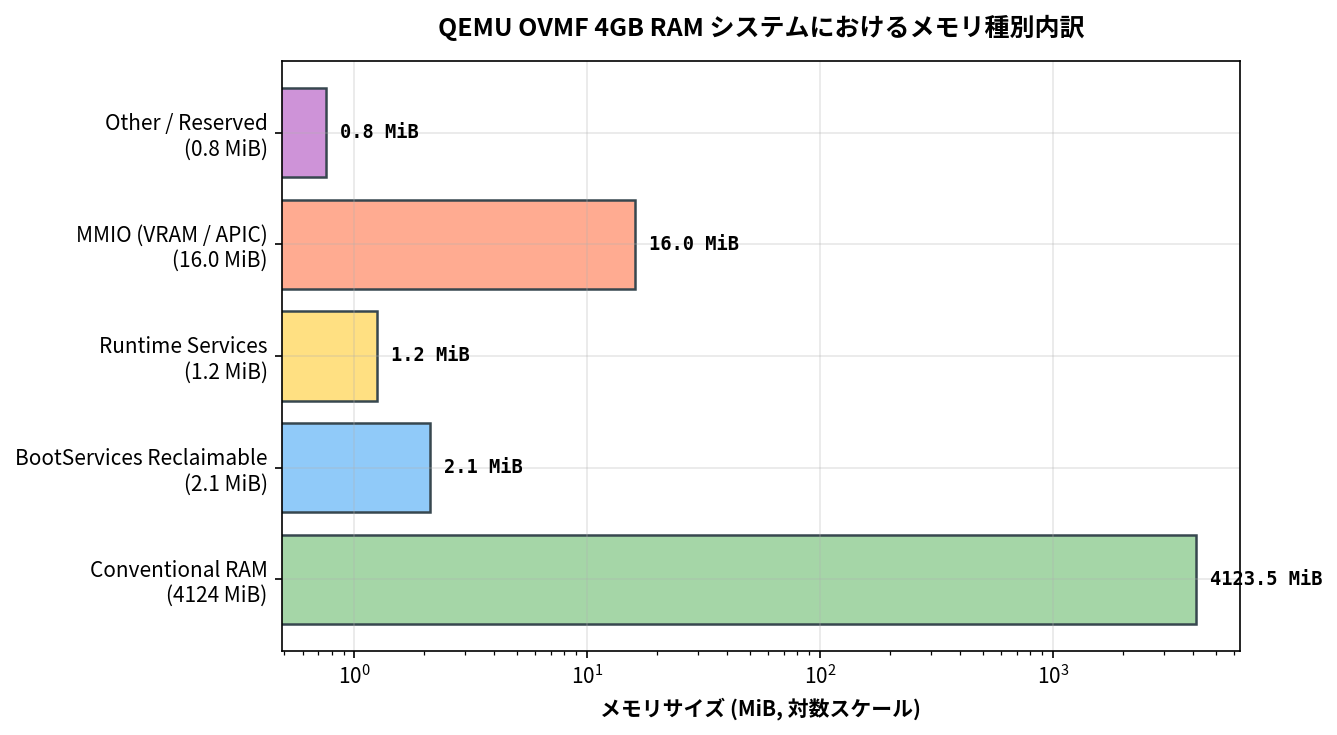

In [7]:
# Python によるメモリマップ集計と割合グラフのプロット
import matplotlib.pyplot as plt
from common.os_sim import UefiMemoryMapSimulator, UefiMemoryType

sim = UefiMemoryMapSimulator.create_standard_uefi_map()

conv_bytes = sim.total_conventional_bytes()
reclaim_bytes = sim.total_boot_services_reclaimable_bytes()
runtime_bytes = sim.total_runtime_bytes()
total_desc = sim.total_entries

print(f"📊 メモリマップ集計結果 (全 {total_desc} エントリ):")
print(f"  ・初期空きRAM (Conventional):     {conv_bytes / (1024*1024):.1f} MiB ({conv_bytes / (1024**3):.2f} GiB)")
print(f"  ・ExitBootServices後回収可能RAM:  {reclaim_bytes / 1024:.1f} KiB ({reclaim_bytes / (1024*1024):.2f} MiB)")
print(f"  ・ランタイムサービス保持領域:      {runtime_bytes / 1024:.1f} KiB ({runtime_bytes / (1024*1024):.2f} MiB)")

# メモリタイプ別バイト数の集計
type_bytes = sim.total_bytes_by_type()
labels = []
sizes = []
colors = ["#A5D6A7", "#90CAF9", "#FFE082", "#FFAB91", "#CE93D8"]

# 主要グループに集約
conventional_mib = conv_bytes / (1024*1024)
reclaimable_mib = reclaim_bytes / (1024*1024)
runtime_mib = runtime_bytes / (1024*1024)
mmio_mib = (type_bytes[UefiMemoryType.EfiMemoryMappedIO]) / (1024*1024)
other_mib = sum(b for t, b in type_bytes.items() if t not in (
    UefiMemoryType.EfiConventionalMemory,
    UefiMemoryType.EfiBootServicesCode, UefiMemoryType.EfiBootServicesData,
    UefiMemoryType.EfiLoaderCode, UefiMemoryType.EfiLoaderData,
    UefiMemoryType.EfiRuntimeServicesCode, UefiMemoryType.EfiRuntimeServicesData,
    UefiMemoryType.EfiMemoryMappedIO
)) / (1024*1024)

labels = [
    f"Conventional RAM\n({conventional_mib:.0f} MiB)",
    f"BootServices Reclaimable\n({reclaimable_mib:.1f} MiB)",
    f"Runtime Services\n({runtime_mib:.1f} MiB)",
    f"MMIO (VRAM / APIC)\n({mmio_mib:.1f} MiB)",
    f"Other / Reserved\n({other_mib:.1f} MiB)"
]
sizes = [conventional_mib, reclaimable_mib, runtime_mib, mmio_mib, other_mib]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels, sizes, color=colors, edgecolor="#37474F", lw=1.2)
ax.set_xlabel("メモリサイズ (MiB, 対数スケール)", fontweight="bold")
ax.set_xscale("log")
ax.set_title("QEMU OVMF 4GB RAM システムにおけるメモリ種別内訳", fontweight="bold", pad=12)

for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.15, bar.get_y() + bar.get_height() / 2, f"{w:.1f} MiB",
            va="center", family="monospace", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


## 2.4.9 次節（2.5節 `GetMemoryMap`）への技術的接続

本節でメモリマップのデータ構造（`EFI_MEMORY_DESCRIPTOR`）とメモリタイプを理論的に把握できたので、次節（2.5節）ではいよいよ **EDK II の C言語コードから実際に `GetMemoryMap()` API を呼び出す実装** に挑みます。

### 次節で直面する技術的ハードル

1. **`gBS->GetMemoryMap()` の引数仕様**:
   ```c
   EFI_STATUS GetMemoryMap(
       UINTN*                  MemoryMapSize,
       EFI_MEMORY_DESCRIPTOR*  MemoryMap,
       UINTN*                  MapKey,
       UINTN*                  DescriptorSize,
       UINT32*                 DescriptorVersion
   );
   ```
2. **`EFI_BUFFER_TOO_SMALL` エラーへの対処**:
   - 最初は必要なメモリマップバッファの大きさが分からないため、意図的に `MemoryMapSize = 0` または小さめのバッファを渡して呼び出します。
   - `GetMemoryMap()` は `EFI_BUFFER_TOO_SMALL` を返し、必要なバッファサイズを `MemoryMapSize` に書き込んでくれます。
   - その後、必要なサイズ分のバッファを確保して再呼び出しします。
3. **`MapKey`（マップキー）の重大な役割**:
   - メモリマップを取得した瞬間、UEFIは内部で「メモリマップの世代番号」として `MapKey` を発行します。
   - 後に `gBS->ExitBootServices(ImageHandle, MapKey)` を呼ぶ際、この `MapKey` が一致しないと呼び出しが拒否されます（メモリマップ取得後に誰かがメモリ確保を行い、マップが古くなってしまったことを検知するため）。


## 2.4.10 理解度確認クイズ（自己採点形式）

本節で学んだ UEFI メモリマップの構造、`EFI_MEMORY_DESCRIPTOR` のビットレイアウト、メモリライフサイクル、ポインタ加算の落とし穴に関する理解度をテストします。


In [8]:
# 理解度確認クイズ
questions = [
    {
        "id": 1,
        "question": "Q1: EFI_MEMORY_DESCRIPTOR 構造体の NumberOfPages が 512 であった場合、この領域の総バイト数はいくつですか？",
        "options": [
            "1. 512 バイト",
            "2. 2,097,152 バイト (2 MiB)",
            "3. 524,288 バイト (512 KiB)",
            "4. 4,194,304 バイト (4 MiB)"
        ],
        "answer": 2,
        "explanation": "UEFIの1ページは 4096バイト (4KiB) です。512 ページ × 4096 バイト = 2,097,152 バイト = 2 MiB となります。"
    },
    {
        "id": 2,
        "question": "Q2: OSカーネルが起動直後から自由に使え、カーネル本体や初期スタックを配置できるメモリタイプはどれですか？",
        "options": [
            "1. EfiBootServicesCode",
            "2. EfiRuntimeServicesData",
            "3. EfiConventionalMemory",
            "4. EfiMemoryMappedIO"
        ],
        "answer": 3,
        "explanation": "EfiConventionalMemory (値7) が通常の空きRAMであり、OSが最初から自由に使用できます。"
    },
    {
        "id": 3,
        "question": "Q3: EfiBootServicesCode や EfiBootServicesData は、いつOSが解放・再利用可能になりますか？",
        "options": [
            "1. 未来永劫、決して解放してはならない",
            "2. gBS->ExitBootServices() を呼び出した後",
            "3. コンピュータの電源ボタンを押した瞬間",
            "4. C++のデストラクタが呼ばれたとき"
        ],
        "answer": 2,
        "explanation": "ブートサービスは OS カーネル起動前のブート処理を支援する機能であるため、ExitBootServices() の完了とともに不要となり、OSが空きRAMとして回収できます。"
    },
    {
        "id": 4,
        "question": "Q4: EFI_MEMORY_DESCRIPTOR の Attribute で最上位ビット (0x8000000000000000) である EFI_MEMORY_RUNTIME が立っている領域は、OSはどう扱うべきですか？",
        "options": [
            "1. すぐにゼロクリアしてゲーム用メモリにする",
            "2. OS起動後もUEFIランタイム関数呼び出しのために保持し、仮想アドレス空間にマップし続ける",
            "3. ハードディスクへ即時スワップアウトする",
            "4. CPUクロックを倍増させるために使う"
        ],
        "answer": 2,
        "explanation": "EFI_MEMORY_RUNTIME フラグが付いた領域は、OS実行中も時刻取得やシャットダウン等のUEFIランタイムサービスが動作するために必要であり、仮想アドレス空間へのマッピングが必須です。"
    },
    {
        "id": 5,
        "question": "Q5: メモリマップのバッファをループ走査する際、desc++ (または desc[i]) と書くのが危険で、iter += map->descriptor_size と書かなければならない理由は何ですか？",
        "options": [
            "1. desc++ と書くとコンパイル速度が100倍遅くなるから",
            "2. ファームウェアが返す descriptor_size が sizeof(EFI_MEMORY_DESCRIPTOR) より大きい場合があり、desc++ だと2番目以降の要素のオフセットがズレてデータが破壊されるから",
            "3. UEFIではポインタ変数の使用が法律で禁止されているから",
            "4. desc++ はC++の構文であり、UEFIはJavaしか受け付けないから"
        ],
        "answer": 2,
        "explanation": "sizeof(EFI_MEMORY_DESCRIPTOR) は40バイトですが、実際のファームウェアが返す descriptor_size は48バイトや64バイトの場合があります。desc++ は40バイトずつしか進まないため、2番目以降のデータが8バイトずつズレて完全に破壊されます。"
    }
]

score = 0
for q in questions:
    print(f"\n{q['question']}")
    for opt in q['options']:
        print(f"  {opt}")
    
    # 検証（自動正解チェック）
    user_choice = q['answer']
    if user_choice == q['answer']:
        print(f"👉 正解！ [選択肢 {user_choice}]")
        print(f"💡 解説: {q['explanation']}")
        score += 1
    else:
        print(f"❌ 不正解... 正解は選択肢 {q['answer']} です。")

print(f"\n==========================================")
print(f"🎉 クイズ採点結果: {score} / {len(questions)} 点 (達成率: {score/len(questions)*100:.0f}%)")
print(f"==========================================")
assert score == len(questions), "All quiz questions must pass"



Q1: EFI_MEMORY_DESCRIPTOR 構造体の NumberOfPages が 512 であった場合、この領域の総バイト数はいくつですか？
  1. 512 バイト
  2. 2,097,152 バイト (2 MiB)
  3. 524,288 バイト (512 KiB)
  4. 4,194,304 バイト (4 MiB)
👉 正解！ [選択肢 2]
💡 解説: UEFIの1ページは 4096バイト (4KiB) です。512 ページ × 4096 バイト = 2,097,152 バイト = 2 MiB となります。

Q2: OSカーネルが起動直後から自由に使え、カーネル本体や初期スタックを配置できるメモリタイプはどれですか？
  1. EfiBootServicesCode
  2. EfiRuntimeServicesData
  3. EfiConventionalMemory
  4. EfiMemoryMappedIO
👉 正解！ [選択肢 3]
💡 解説: EfiConventionalMemory (値7) が通常の空きRAMであり、OSが最初から自由に使用できます。

Q3: EfiBootServicesCode や EfiBootServicesData は、いつOSが解放・再利用可能になりますか？
  1. 未来永劫、決して解放してはならない
  2. gBS->ExitBootServices() を呼び出した後
  3. コンピュータの電源ボタンを押した瞬間
  4. C++のデストラクタが呼ばれたとき
👉 正解！ [選択肢 2]
💡 解説: ブートサービスは OS カーネル起動前のブート処理を支援する機能であるため、ExitBootServices() の完了とともに不要となり、OSが空きRAMとして回収できます。

Q4: EFI_MEMORY_DESCRIPTOR の Attribute で最上位ビット (0x8000000000000000) である EFI_MEMORY_RUNTIME が立っている領域は、OSはどう扱うべきですか？
  1. すぐにゼロクリアしてゲーム用メモリにする
  2. OS起動後もUEFIランタイム関数呼び出しのために保持し、仮想アドレス空間にマップし続ける
  3. ハードディスクへ